# Notebook 3: Treino, Modelação e Otimização de Hiperparâmetros

**Unidade Curricular:** Dados e Aprendizagem Automática (DAA) — 2026/2027

Neste notebook treinamos e avaliamos modelos para prever a faixa etária (`AGE_RANGE`). A métrica é o **Macro F1**, a mesma da competição. Começamos por um modelo de referência simples, que serve de ponto de partida para as melhorias seguintes.

## 1. Configuração e Carregamento dos Dados

Carregamos os dados codificados no Notebook 2.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

warnings.filterwarnings('ignore', category=FutureWarning)
plt.style.use('ggplot')

DATA_DIR = '../data'
SUBMISSIONS_DIR = '../submissions'
TARGET = 'AGE_RANGE'
RANDOM_STATE = 42

train_df = pd.read_csv(os.path.join(DATA_DIR, 'train_nb02.csv'), index_col='PID')
test_df = pd.read_csv(os.path.join(DATA_DIR, 'test_nb02.csv'), index_col='PID')

X = train_df.drop(columns=TARGET)
y = train_df[TARGET]
X_test = test_df[X.columns]

print(f"X: {X.shape} | y: {y.shape} | X_test: {X_test.shape}")

X: (10962, 409) | y: (10962,) | X_test: (3655, 409)


## 2. Modelo de Referência: Árvore de Decisão

Treinamos uma árvore de decisão com `class_weight='balanced'`, que dá mais peso às faixas etárias menos representadas, importante para o Macro F1. O desempenho é estimado com **validação cruzada estratificada em 5 partes** (cada parte mantém as proporções das classes), testando várias profundidades máximas da árvore para evitar *overfitting*.

,max_depth,F1 médio,Desvio padrão
0,4,0.3065,0.0119
1,6,0.3729,0.0148
2,8,0.4072,0.0057
3,10,0.4035,0.0102
4,12,0.3922,0.0100
5,15,0.3761,0.0085
6,None,0.3662,0.0114


Melhor profundidade: 8 (Macro F1 = 0.4072)


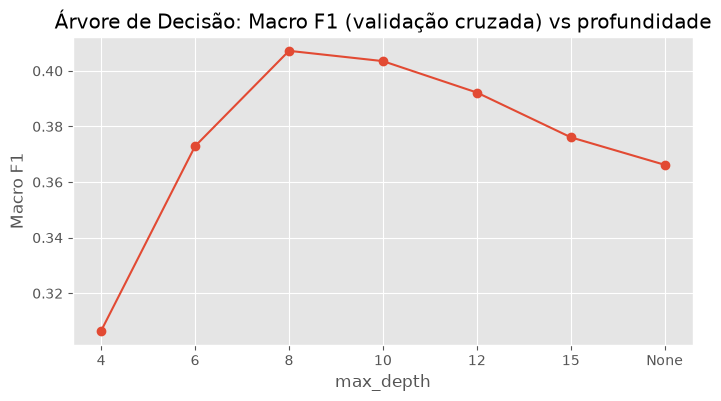

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

resultados = []
for profundidade in [4, 6, 8, 10, 12, 15, None]:
    arvore = DecisionTreeClassifier(max_depth=profundidade, class_weight='balanced',
                                    random_state=RANDOM_STATE)
    notas = cross_val_score(arvore, X, y, cv=cv, scoring='f1_macro')
    resultados.append({'max_depth': str(profundidade), 'F1 médio': notas.mean(), 'Desvio padrão': notas.std()})

resultados_df = pd.DataFrame(resultados).round(4)
display(resultados_df)

melhor = resultados_df.loc[resultados_df['F1 médio'].idxmax()]
print(f"Melhor profundidade: {melhor['max_depth']} (Macro F1 = {melhor['F1 médio']:.4f})")

resultados_df.plot(x='max_depth', y='F1 médio', marker='o', legend=False, figsize=(8, 4),
                   title='Árvore de Decisão: Macro F1 (validação cruzada) vs profundidade')
plt.ylabel('Macro F1')
plt.show()

## 3. Primeira Submissão

Treinamos a árvore com a melhor profundidade em todo o conjunto de treino e geramos as previsões para o teste, no formato pedido pela competição (uma coluna `AGE_RANGE`, uma linha por pessoa, pela ordem original).

In [3]:
profundidade = None if melhor['max_depth'] == 'None' else int(melhor['max_depth'])
arvore = DecisionTreeClassifier(max_depth=profundidade, class_weight='balanced', random_state=RANDOM_STATE)
arvore.fit(X, y)
previsoes = arvore.predict(X_test)

# O ficheiro de exemplo do Kaggle serve de molde (RowId + AGE_RANGE)
exemplo = pd.read_csv(os.path.join(DATA_DIR, 'example_submission_10.csv'))
print("Formato do exemplo:")
display(exemplo.head())

assert len(exemplo) == len(previsoes) == 3655, "O nº de linhas não coincide"
submissao = exemplo.copy()
submissao[TARGET] = previsoes

caminho = os.path.join(SUBMISSIONS_DIR, 'sub01_arvore_referencia.csv')
submissao.to_csv(caminho, index=False)
print(f"Submissão guardada em {caminho}")
display(submissao.head())

Formato do exemplo:


,RowId,AGE_RANGE
0,0,10
1,1,10
2,2,10
3,3,10
4,4,10


Submissão guardada em ../submissions/sub01_arvore_referencia.csv


,RowId,AGE_RANGE
0,0,3
1,1,2
2,2,10
3,3,6
4,4,10


> **Conclusão:** o melhor resultado é obtido com `max_depth=8` (Macro F1 = 0,407 ± 0,006), cerca de sete vezes acima do classificador aleatório (0,06). Profundidades menores levam a *underfitting* (0,31 com profundidade 4); profundidades maiores levam a *overfitting*, com o desempenho a descer até 0,369 numa árvore sem limite. Este valor é a **referência** para os modelos seguintes.